# 프로젝트 : 네이버 영화리뷰 감성분석 도전하기

## 실험 개요

NSMC(네이버 영화리뷰) 이진 감성분류에서 아래 세 가지를 확인하는 것을 목표로 했다.

- RQ1. 같은 전처리·같은 임베딩 차원에서 모델 구조(LSTM, 1D-CNN, GlobalMaxPool)에 따라 성능이 얼마나 달라지는가? 신경망 없이 TF-IDF + 로지스틱 회귀만 써도 어느 정도 나오는가?
- RQ2. 노드에서 RNN은 pre padding이 post보다 크게 유리하다고 했는데, 문장이 짧은 NSMC에서도 그런가?
- RQ3. 사전학습 word2vec_ko로 임베딩을 초기화하면 성능이 오르는가? 오른다면 임베딩을 고정해도 오르는가, 같이 학습해야 오르는가?

실험 규칙
- 전처리, 사전(10,000개, train에서만 생성), maxlen, 임베딩 차원(100), optimizer(Adam, lr 1e-3), batch(256), early stopping(val loss, patience 2)은 모든 신경망 모델에 똑같이 적용했다. 비교할 때 바꾸는 조건은 한 번에 하나만 두었다.
- train에서 10%를 떼어 validation으로 쓰고, 모델과 epoch 선택은 validation으로만 했다. test는 학습이 끝난 뒤 보고용으로만 평가했고, test 결과를 보고 설정을 다시 바꾸지 않았다.
- 신경망 모델은 seed 42, 43, 44로 3번씩 학습해서 평균 ± 표준편차로 비교했다. 단일 실행 차이가 seed 차이보다 작으면 차이가 있다고 보지 않았다.
- 주요 비교(LSTM vs LSTM+word2vec)는 같은 test 문장에 대한 예측을 짝지어 McNemar 검정도 했다.

이전 스텝까지는 영문 텍스트의 감정 분석을 진행해 보았습니다. 그렇다면 이번에는 한국어 텍스트의 감정 분석을 진행해 보면 어떨까요? 오늘 활용할 데이터셋은 네이버 영화의 댓글을 모아 구성된 [Naver sentiment movie corpus](https://github.com/e9t/nsmc)입니다.

아래와 같이 다운로드를 진행해 주세요.



```
$ wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
$ wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt
$ mv ratings_*.txt ~/aiffel/sentiment_classification/data
$ pip install konlpy
$ sudo apt-get install git
$ sudo apt-get install curl
$ bash <(curl -s https://raw.githubusercontent.com/konlpy/konlpy/master/scripts/mecab.sh)

```

프로젝트 진행 순서는 다음과 같습니다.



In [1]:
!wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
!wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt
!mv ratings_*.txt /content/data
!pip install konlpy
!sudo apt-get install git
!sudo apt-get install curl
# !bash <(curl -s https://raw.githubusercontent.com/konlpy/konlpy/master/scripts/mecab.sh)

--2026-11-08 08:14:58--  https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14628807 (14M) [text/plain]
Saving to: ‘ratings_train.txt’

ratings_train.txt   100%[===================>]  13.95M  --.-KB/s    in 0.08s   

2026-11-08 08:14:58 (178 MB/s) - ‘ratings_train.txt’ saved [14628807/14628807]

--2026-11-08 08:14:58--  https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4893335 (4.7M) [application/octet-

In [2]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 54.9 MB/s  0:00:00


## 라이브러리 버전을 확인해 봅니다
---
사용할 라이브러리 버전을 둘러봅시다.

In [3]:
import pandas
import konlpy
import gensim

print(pandas.__version__)
print(konlpy.__version__)
print(gensim.__version__)

2.2.3
0.6.0
4.4.0


## 1) 데이터 준비와 확인
---

In [4]:
import pandas as pd

# 데이터를 읽어봅시다.
train_data = pd.read_table('/content/ratings_train.txt')
test_data = pd.read_table('/content/ratings_test.txt')

train_data.head()

,id,document,label
0,9976970,아 더빙.. 진짜 짜증나네요 목소리,0
1,3819312,흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나,1
2,10265843,너무재밓었다그래서보는것을추천한다,0
3,9045019,교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정,0
4,6483659,사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 ...,1


## 2) 데이터로더 구성
---
실습 때 다루었던 IMDB 데이터셋은 텍스트를 가공하여 `imdb.data_loader()` 메서드를 호출하면 숫자 인덱스로 변환된 텍스트와 `word_to_index` 딕셔너리까지 친절하게 제공합니다. 그러나 이번에 다루게 될 nsmc 데이터셋은 전혀 가공되지 않은 텍스트 파일로 이루어져 있습니다. 이것을 읽어서 `imdb.data_loader()`와 동일하게 동작하는 자신만의 `data_loader`를 만들어 보는 것으로 시작합니다. `data_loader` 안에서는 다음을 수행해야 합니다.

- 데이터의 중복 제거
- NaN 결측치 제거
- 한국어 토크나이저로 토큰화
- 불용어(Stopwords) 제거
- 사전`word_to_index` 구성
- 텍스트 스트링을 사전 인덱스 스트링으로 변환
- `X_train`, `y_train`, `X_test`, `y_test`, `word_to_index` 리턴

In [5]:
## 코랩 Mecab() 설치를 위한 추가 코드_1

!pip install Korpora

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [Korpora]


In [6]:
## 코랩 Mecab() 설치를 위한 추가 코드_2

!git clone https://github.com/SOMJANG/Mecab-ko-for-Google-Colab.git

Cloning into 'Mecab-ko-for-Google-Colab'...
remote: Enumerating objects: 138, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 138 (delta 26), reused 22 (delta 8), pack-reused 91 (from 1)
Receiving objects: 100% (138/138), 1.72 MiB | 4.63 MiB/s, done.
Resolving deltas: 100% (65/65), done.


In [7]:
## 코랩 Mecab() 설치를 위한 추가 코드_3

%cd Mecab-ko-for-Google-Colab/

/content/Mecab-ko-for-Google-Colab


In [8]:
## 코랩 Mecab() 설치를 위한 추가 코드_4

# !bash install_mecab-ko_on_colab_light_220429.sh

In [9]:
%pip install -q python-mecab-ko

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for python-mecab-ko (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for python-mecab-ko
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> python-mecab-ko


In [10]:
from mecab import MeCab
import numpy as np
from collections import Counter

tokenizer = MeCab()
stopwords = ['의','가','이','은','들','는','좀','잘','걍','과','도','를','으로','자','에','와','한','하다']

def load_data(train_data, test_data, num_words=10000):
    train_data.drop_duplicates(subset=['document'], inplace=True)
    train_data = train_data.dropna(how = 'any')
    test_data.drop_duplicates(subset=['document'], inplace=True)
    test_data = test_data.dropna(how = 'any')

    X_train = []
    for sentence in train_data['document']:
        temp_X = tokenizer.morphs(sentence) # 토큰화
        temp_X = [word for word in temp_X if not word in stopwords] # 불용어 제거
        X_train.append(temp_X)

    X_test = []
    for sentence in test_data['document']:
        temp_X = tokenizer.morphs(sentence) # 토큰화
        temp_X = [word for word in temp_X if not word in stopwords] # 불용어 제거
        X_test.append(temp_X)

    words = np.concatenate(X_train).tolist()
    counter = Counter(words)
    counter = counter.most_common(10000-4)
    vocab = ['', '', '', ''] + [key for key, _ in counter]
    word_to_index = {word:index for index, word in enumerate(vocab)}

    def wordlist_to_indexlist(wordlist):
        return [word_to_index[word] if word in word_to_index else word_to_index[''] for word in wordlist]

    X_train = list(map(wordlist_to_indexlist, X_train))
    X_test = list(map(wordlist_to_indexlist, X_test))

    return X_train, np.array(list(train_data['label'])), X_test, np.array(list(test_data['label'])), word_to_index

X_train, y_train, X_test, y_test, word_to_index = load_data(train_data, test_data)

ModuleNotFoundError: No module named 'mecab'

원본 셀의 `python-mecab-ko`는 현재 Colab(Python 3.13)에서 wheel 빌드가 실패했고, 그래서 바로 위 셀의 `from mecab import MeCab`도 `ModuleNotFoundError`가 났다. 지난 단어사전 프로젝트에서 동작했던 KoNLPy + `mecab-ko` + `mecab-python3` 조합으로 설치를 바꿨다.

또 원본 `load_data`는 특수 토큰 자리가 빈 문자열 네 개(`['', '', '', '']`)라서 딕셔너리를 만들면 네 개가 키 하나로 합쳐지고 `''`만 인덱스 3으로 남는다. 이렇게 되면 0번(`<PAD>`)과 1·2번 자리가 비고, 아래 `get_encoded_sentence`처럼 `'<BOS>'`, `'<UNK>'`를 찾는 코드는 KeyError가 난다. 그래서 `<PAD>`, `<BOS>`, `<UNK>`, `<UNUSED>`를 명시해서 다시 작성했다. 단어사전은 train 데이터에서만 만들었다.

In [11]:
%pip install -q konlpy mecab-ko mecab-python3

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [12]:
import os
import importlib
import numpy as np
from collections import Counter
import mecab_ko_dic

os.environ['MECABRC'] = os.path.join(mecab_ko_dic.DICDIR, 'mecabrc')

# 위 6번 셀에서 konlpy를 이미 import한 상태라, 설치 후 Mecab 모듈을 다시 읽어야 Tagger를 찾는다.
import konlpy.tag._mecab as mecab_module
importlib.reload(mecab_module)
tokenizer = mecab_module.Mecab(dicpath=mecab_ko_dic.DICDIR)
print(tokenizer.morphs('이 영화 진짜 재밌었는데 결말이 좀 아쉬웠다'))

stopwords = ['의','가','이','은','들','는','좀','잘','걍','과','도','를','으로','자','에','와','한','하다']

def load_data(train_data, test_data, num_words=10000):
    """중복·결측 제거 → 형태소 토큰화 → 불용어 제거 → train 기준 사전 → 인덱스 변환"""
    train_data = train_data.drop_duplicates(subset=['document']).dropna(how='any')
    test_data = test_data.drop_duplicates(subset=['document']).dropna(how='any')

    def tokenize(sentences):
        result = []
        for sentence in sentences:
            tokens = tokenizer.morphs(sentence)
            result.append([w for w in tokens if w not in stopwords])
        return result

    X_train = tokenize(train_data['document'])
    X_test = tokenize(test_data['document'])

    # 빈도 상위 단어로 사전을 만든다. 앞의 4칸은 특수 토큰 자리
    counter = Counter(w for sentence in X_train for w in sentence)
    vocab = ['<PAD>', '<BOS>', '<UNK>', '<UNUSED>'] + [w for w, _ in counter.most_common(num_words - 4)]
    word_to_index = {word: index for index, word in enumerate(vocab)}

    def wordlist_to_indexlist(wordlist):
        return [word_to_index.get(word, word_to_index['<UNK>']) for word in wordlist]

    X_train = list(map(wordlist_to_indexlist, X_train))
    X_test = list(map(wordlist_to_indexlist, X_test))
    return X_train, np.array(train_data['label']), X_test, np.array(test_data['label']), word_to_index

X_train, y_train, X_test, y_test, word_to_index = load_data(train_data, test_data)
print('train:', len(X_train), '/ test:', len(X_test), '/ vocab:', len(word_to_index))
print('train 긍정 비율: {:.4f}, test 긍정 비율: {:.4f}'.format(y_train.mean(), y_test.mean()))

# 오류 분석에서 원문을 보려고, load_data와 같은 순서로 정제한 test 원문을 따로 둔다.
test_docs = test_data.drop_duplicates(subset=['document']).dropna(how='any')['document'].tolist()
assert len(test_docs) == len(X_test)

['이', '영화', '진짜', '재밌', '었', '는데', '결말', '이', '좀', '아쉬웠', '다']
train: 146182 / test: 49157 / vocab: 10000
train 긍정 비율: 0.4983, test 긍정 비율: 0.5027


In [13]:
index_to_word = {index:word for word, index in word_to_index.items()}

In [14]:
# 문장 1개를 활용할 딕셔너리와 함께 주면, 단어 인덱스 리스트 벡터로 변환해 주는 함수입니다.
# 단, 모든 문장은 <BOS>로 시작하는 것으로 합니다.
def get_encoded_sentence(sentence, word_to_index):
    return [word_to_index['<BOS>']]+[word_to_index[word] if word in word_to_index else word_to_index['<UNK>'] for word in sentence.split()]

# 여러 개의 문장 리스트를 한꺼번에 단어 인덱스 리스트 벡터로 encode해 주는 함수입니다.
def get_encoded_sentences(sentences, word_to_index):
    return [get_encoded_sentence(sentence, word_to_index) for sentence in sentences]

# 숫자 벡터로 encode된 문장을 원래대로 decode하는 함수입니다.
def get_decoded_sentence(encoded_sentence, index_to_word):
    return ' '.join(index_to_word[index] if index in index_to_word else '<UNK>' for index in encoded_sentence[1:])  #[1:]를 통해 <BOS>를 제외

# 여러 개의 숫자 벡터로 encode된 문장을 한꺼번에 원래대로 decode하는 함수입니다.
def get_decoded_sentences(encoded_sentences, index_to_word):
    return [get_decoded_sentence(encoded_sentence, index_to_word) for encoded_sentence in encoded_sentences]

## 3) 모델 구성을 위한 데이터 분석 및 가공
---
- 데이터셋 내 문장 길이 분포
- 적절한 최대 문장 길이 지정
- keras.preprocessing.sequence.pad_sequences 을 활용한 패딩 추가

문장길이 평균 :  15.952784884595914
문장길이 최대 :  116
문장길이 표준편차 :  12.816172318652985
pad_sequences maxlen :  41
train 문장 중 maxlen 이하 비율: 0.9343
토큰이 0개인 문장 수: train 3, test 2
test 토큰 중 <UNK> 비율: 0.0465
<UNK>가 하나 이상 있는 test 문장 비율: 0.4150


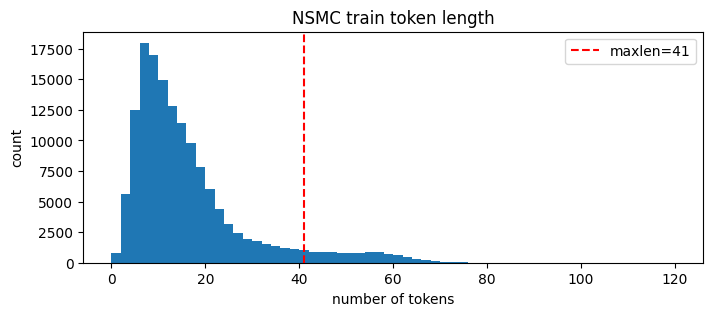

In [15]:
import matplotlib.pyplot as plt

# maxlen은 train 문장 길이로만 정한다 (test 분포를 보고 정하면 test 정보가 새어 들어간다)
lengths = np.array([len(s) for s in X_train])
print('문장길이 평균 : ', np.mean(lengths))
print('문장길이 최대 : ', np.max(lengths))
print('문장길이 표준편차 : ', np.std(lengths))

maxlen = int(np.mean(lengths) + 2 * np.std(lengths))
print('pad_sequences maxlen : ', maxlen)
print('train 문장 중 maxlen 이하 비율: {:.4f}'.format(np.mean(lengths <= maxlen)))
print('토큰이 0개인 문장 수: train {}, test {}'.format(np.sum(lengths == 0), sum(len(s) == 0 for s in X_test)))

# 사전 크기 10,000이 test를 얼마나 덮는지 확인 (<UNK> = 2)
test_tokens = np.concatenate([s for s in X_test if len(s)])
print('test 토큰 중 <UNK> 비율: {:.4f}'.format(np.mean(test_tokens == 2)))
print('<UNK>가 하나 이상 있는 test 문장 비율: {:.4f}'.format(np.mean([2 in s for s in X_test])))

plt.figure(figsize=(8, 3))
plt.hist(lengths, bins=60, range=(0, 120))
plt.axvline(maxlen, color='red', linestyle='--', label=f'maxlen={maxlen}')
plt.xlabel('number of tokens')
plt.ylabel('count')
plt.title('NSMC train token length')
plt.legend()
plt.show()

train 문장은 평균 약 16토큰, 최대 116토큰이고 대부분 30토큰 아래에 몰려 있다. 노드 실습처럼 평균 + 2×표준편차로 maxlen을 정하니 41이 나왔고, train 문장의 93.4%가 이 길이 안에 들어간다. 잘리는 6.6%가 실제로 손해를 보는지는 9) 오류 분석에서 길이 구간별 정확도로 다시 확인했다.

사전 10,000개 기준으로 test 토큰의 4.65%가 <UNK>가 되고, <UNK>가 하나라도 들어간 test 문장은 41.5%다. 문장 수로 보면 적지 않아서 사전 크기도 성능의 상한을 정하는 요인일 수 있다. 이번 실험은 모든 모델이 같은 사전을 쓰기 때문에 모델 사이의 비교에는 영향이 없다. 형태소 분석 후 불용어를 빼면 토큰이 하나도 남지 않는 문장도 train 3개, test 2개 있었다.

In [16]:
import torch

def pad_sequences(sequences, maxlen, padding='pre'):
    """길이를 maxlen으로 맞춘다. 긴 문장은 앞 maxlen개만 남기고, 짧은 문장은 padding 방향에 0(<PAD>)을 채운다."""
    padded = np.zeros((len(sequences), maxlen), dtype=np.int64)
    for i, seq in enumerate(sequences):
        seq = seq[:maxlen]
        if len(seq) == 0:
            continue
        if padding == 'pre':
            padded[i, -len(seq):] = seq
        else:
            padded[i, :len(seq)] = seq
    return torch.tensor(padded)

X_train_pre = pad_sequences(X_train, maxlen, 'pre')
X_test_pre = pad_sequences(X_test, maxlen, 'pre')
print(X_train_pre.shape, X_test_pre.shape)
print(X_train_pre[0])
print(get_decoded_sentence([1] + X_train[0], index_to_word))

torch.Size([146182, 41]) torch.Size([49157, 41])
tensor([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,  32, 604,   4,   4,  39, 229,  20,  33, 742])
아 더빙 . . 진짜 짜증 나 네요 목소리


## 4) 모델 구성 및 validation set 구성
---
모델은 3가지 이상 다양하게 구성하여 실험해 보세요.

In [17]:
import random
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from gensim.models import KeyedVectors

SEEDS = [42, 43, 44]
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '/', torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

# validation은 train에서 10%를 라벨 비율을 유지해서 떼어낸다. 분할은 seed와 상관없이 고정한다.
idx_tr, idx_val = train_test_split(np.arange(len(X_train)), test_size=0.1, stratify=y_train, random_state=42)
print('train / val / test:', len(idx_tr), len(idx_val), len(X_test))

# 8)에서 같은 구조에 사전학습 임베딩만 바꿔 넣으려고, 임베딩 차원을 word2vec_ko와 맞춘다.
# word2vec_ko.model은 LMS 실습환경의 /data에만 있어서, 그 환경(gensim 4.3.2)에서 아래처럼 KeyedVectors만 저장한 뒤 Colab /content에 올렸다.
#   m = Word2VecKeyedVectors.load('/data/word2vec_ko.model')   # Word2Vec 모델
#   m.wv.save('word2vec_ko.kv')                                  # 유사도·임베딩에 필요한 단어 벡터만
word2vec_path = '/content/word2vec_ko.kv'
w2v = KeyedVectors.load(word2vec_path)
vocab_size = len(word_to_index)
word_vector_dim = w2v.vector_size
print('word2vec_ko 단어 수:', len(w2v.index_to_key), '/ 차원:', word_vector_dim)

def make_loaders(X, X_test_, batch_size=256):
    y = torch.tensor(y_train, dtype=torch.float32)
    tr, va = torch.as_tensor(idx_tr), torch.as_tensor(idx_val)
    g = torch.Generator().manual_seed(0)
    train_loader = DataLoader(TensorDataset(X[tr], y[tr]), batch_size=batch_size, shuffle=True, generator=g)
    val_loader = DataLoader(TensorDataset(X[va], y[va]), batch_size=1024)
    test_loader = DataLoader(TensorDataset(X_test_, torch.tensor(y_test, dtype=torch.float32)), batch_size=1024)
    return train_loader, val_loader, test_loader

loaders_pre = make_loaders(X_train_pre, X_test_pre)

device: cuda / Tesla T4
train / val / test: 131563 14619 49157
word2vec_ko 단어 수: 302960 / 차원: 100


In [18]:
import torch.nn as nn

class LSTMClassifier(nn.Module):
    """Embedding → LSTM → 마지막 hidden state → 분류. pre padding이면 마지막 시점이 실제 단어다."""
    def __init__(self, vocab_size, word_vector_dim, hidden=128, embedding_matrix=None, freeze_embedding=False):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, word_vector_dim, padding_idx=0)
        if embedding_matrix is not None:
            self.embedding.weight.data.copy_(torch.tensor(embedding_matrix, dtype=torch.float32))
        self.embedding.weight.requires_grad = not freeze_embedding
        self.lstm = nn.LSTM(word_vector_dim, hidden, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        _, (h_n, _) = self.lstm(self.embedding(x))
        return self.fc(self.dropout(h_n[-1])).squeeze(-1)

class CNN1DClassifier(nn.Module):
    """Embedding → Conv1d 두 번 → Global max pooling. 5단어 범위의 패턴을 잡는다."""
    def __init__(self, vocab_size, word_vector_dim, channels=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, word_vector_dim, padding_idx=0)
        self.conv1 = nn.Conv1d(word_vector_dim, channels, kernel_size=5, padding=2)
        self.conv2 = nn.Conv1d(channels, channels, kernel_size=5, padding=2)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(channels, 1)

    def forward(self, x):
        h = self.embedding(x).permute(0, 2, 1)          # (batch, dim, len)
        h = torch.relu(self.conv1(h))
        h = torch.relu(self.conv2(h))
        h = h.max(dim=2).values                         # global max pooling
        return self.fc(self.dropout(h)).squeeze(-1)

class GMPClassifier(nn.Module):
    """Embedding → Global max pooling → FFN. 순서 정보 없이 가장 강한 단어 특징만 쓰는 기준 모델"""
    def __init__(self, vocab_size, word_vector_dim, hidden=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, word_vector_dim, padding_idx=0)
        self.fc1 = nn.Linear(word_vector_dim, hidden)
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(hidden, 1)

    def forward(self, x):
        h = self.embedding(x).max(dim=1).values
        return self.fc2(self.dropout(torch.relu(self.fc1(h)))).squeeze(-1)

for m in [LSTMClassifier(vocab_size, word_vector_dim), CNN1DClassifier(vocab_size, word_vector_dim), GMPClassifier(vocab_size, word_vector_dim)]:
    n_all = sum(p.numel() for p in m.parameters())
    print(f'{m.__class__.__name__:<16} 전체 {n_all:,} / 임베딩 제외 {n_all - vocab_size * word_vector_dim:,} params')

LSTMClassifier   전체 1,117,889 / 임베딩 제외 117,889 params
CNN1DClassifier  전체 1,146,305 / 임베딩 제외 146,305 params
GMPClassifier    전체 1,006,529 / 임베딩 제외 6,529 params


세 모델 모두 파라미터의 대부분(1,000,000개)이 임베딩이고, 임베딩을 뺀 부분은 LSTM 약 12만, 1D-CNN 약 15만, GlobalMaxPool 약 6천 개다. 그래서 GlobalMaxPool은 구조뿐 아니라 용량도 가장 작은 모델이라는 점을 감안하고 비교했다.

## 5) 모델 훈련 개시
---

In [19]:
import copy, time

def run_epoch(model, loader, loss_fn, optimizer=None):
    model.train(optimizer is not None)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(optimizer is not None):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = loss_fn(logits, y)
            if optimizer is not None:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += ((logits > 0).float() == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

@torch.no_grad()
def predict_proba(model, loader):
    model.eval()
    return np.concatenate([torch.sigmoid(model(x.to(device))).cpu().numpy() for x, _ in loader])

def train_model(name, model, train_loader, val_loader, epochs=10, patience=2, lr=1e-3, verbose=True):
    """val loss가 patience번 연속 나빠지면 멈추고, val loss가 가장 낮았던 epoch의 가중치로 되돌린다."""
    model.to(device)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_loss, best_state, best_epoch, wait = float('inf'), None, 0, 0
    for epoch in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, loss_fn, optimizer)
        vl, va = run_epoch(model, val_loader, loss_fn)
        for k, v in zip(history, [tl, ta, vl, va]):
            history[k].append(v)
        if verbose:
            print(f'[{name}] epoch {epoch:2d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}')
        if vl < best_loss:
            best_loss, best_state, best_epoch, wait = vl, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return {'model': model, 'history': history, 'best_epoch': best_epoch, 'val_acc': history['val_acc'][best_epoch - 1]}

all_runs = {}

def run_config(name, build_model, loaders):
    """같은 설정을 SEEDS마다 학습한다. 선택은 run마다 val loss로 하고, test는 끝난 뒤 보고용으로만 계산한다."""
    train_loader, val_loader, test_loader = loaders
    all_runs[name] = {}
    start = time.time()
    for seed in SEEDS:
        set_seed(seed)
        train_loader.generator.manual_seed(seed)   # 배치 순서도 seed에 맞춰 고정
        r = train_model(f'{name}/seed{seed}', build_model(), train_loader, val_loader, verbose=(seed == SEEDS[0]))
        r['test_proba'] = predict_proba(r['model'], test_loader)
        r['test_acc'] = np.mean((r['test_proba'] > 0.5) == y_test)
        all_runs[name][seed] = r
        print(f'  {name} seed {seed}: best epoch {r["best_epoch"]}, val acc {r["val_acc"]:.4f}')
    print(f'  ({time.time() - start:.0f}s)')

In [20]:
run_config('LSTM', lambda: LSTMClassifier(vocab_size, word_vector_dim), loaders_pre)
run_config('1D-CNN', lambda: CNN1DClassifier(vocab_size, word_vector_dim), loaders_pre)
run_config('GlobalMaxPool', lambda: GMPClassifier(vocab_size, word_vector_dim), loaders_pre)

[LSTM/seed42] epoch  1 | train loss 0.4603 acc 0.7762 | val loss 0.3725 acc 0.8298
[LSTM/seed42] epoch  2 | train loss 0.3453 acc 0.8474 | val loss 0.3459 acc 0.8460
[LSTM/seed42] epoch  3 | train loss 0.3138 acc 0.8654 | val loss 0.3291 acc 0.8567
[LSTM/seed42] epoch  4 | train loss 0.2771 acc 0.8839 | val loss 0.3233 acc 0.8600
[LSTM/seed42] epoch  5 | train loss 0.2512 acc 0.8963 | val loss 0.3257 acc 0.8618
[LSTM/seed42] epoch  6 | train loss 0.2250 acc 0.9093 | val loss 0.3266 acc 0.8612
  LSTM seed 42: best epoch 4, val acc 0.8600
  LSTM seed 43: best epoch 4, val acc 0.8599
  LSTM seed 44: best epoch 4, val acc 0.8591
  (79s)
[1D-CNN/seed42] epoch  1 | train loss 0.4544 acc 0.7757 | val loss 0.3684 acc 0.8275
[1D-CNN/seed42] epoch  2 | train loss 0.3392 acc 0.8505 | val loss 0.3453 acc 0.8459
[1D-CNN/seed42] epoch  3 | train loss 0.2896 acc 0.8760 | val loss 0.3345 acc 0.8537
[1D-CNN/seed42] epoch  4 | train loss 0.2526 acc 0.8938 | val loss 0.3481 acc 0.8513
[1D-CNN/seed42] epo

노드에서 RNN은 padding 방향에 따라 성능이 달라진다고 해서(RQ2), LSTM만 같은 조건에서 `post` padding으로 다시 학습했다. 위 LSTM은 `pre` padding이고, 마지막 hidden state를 쓰기 때문에 `post`면 문장 끝에 붙은 0들을 지나온 상태로 분류하게 된다.

In [21]:
loaders_post = make_loaders(pad_sequences(X_train, maxlen, 'post'), pad_sequences(X_test, maxlen, 'post'))
run_config('LSTM-post', lambda: LSTMClassifier(vocab_size, word_vector_dim), loaders_post)

[LSTM-post/seed42] epoch  1 | train loss 0.5840 acc 0.6454 | val loss 0.4030 acc 0.8120
[LSTM-post/seed42] epoch  2 | train loss 0.3739 acc 0.8347 | val loss 0.3629 acc 0.8455
[LSTM-post/seed42] epoch  3 | train loss 0.3221 acc 0.8631 | val loss 0.3412 acc 0.8541
[LSTM-post/seed42] epoch  4 | train loss 0.2877 acc 0.8803 | val loss 0.3239 acc 0.8590
[LSTM-post/seed42] epoch  5 | train loss 0.2605 acc 0.8942 | val loss 0.3253 acc 0.8592
[LSTM-post/seed42] epoch  6 | train loss 0.2344 acc 0.9060 | val loss 0.3349 acc 0.8604
  LSTM-post seed 42: best epoch 4, val acc 0.8590
  LSTM-post seed 43: best epoch 4, val acc 0.8607
  LSTM-post seed 44: best epoch 5, val acc 0.8640
  (79s)


신경망 없이 어느 정도까지 되는지 보려고(RQ1), 같은 토큰(사전 10,000개, <UNK> 포함)으로 TF-IDF(unigram+bigram) + 로지스틱 회귀를 비교 기준으로 두었다. 규제 강도 C는 validation으로만 골랐다.

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

as_text = lambda seqs: [' '.join(map(str, s)) for s in seqs]
tfidf = TfidfVectorizer(token_pattern=r'\S+', ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr_tfidf = tfidf.fit_transform(as_text([X_train[i] for i in idx_tr]))
Xval_tfidf = tfidf.transform(as_text([X_train[i] for i in idx_val]))
Xte_tfidf = tfidf.transform(as_text(X_test))
print('TF-IDF 특성 수:', Xtr_tfidf.shape[1])

best_c, best_val = None, -1
for C in [0.5, 1, 2, 4]:
    clf = LogisticRegression(C=C, max_iter=2000).fit(Xtr_tfidf, y_train[idx_tr])
    val_acc = clf.score(Xval_tfidf, y_train[idx_val])
    print(f'C={C}: val acc {val_acc:.4f}')
    if val_acc > best_val:
        best_c, best_val, best_clf = C, val_acc, clf
baseline = {'C': best_c, 'val_acc': best_val, 'test_acc': best_clf.score(Xte_tfidf, y_test)}
print('선택한 C:', best_c)

TF-IDF 특성 수: 152559
C=0.5: val acc 0.8617
C=1: val acc 0.8659
C=2: val acc 0.8691
C=4: val acc 0.8689
선택한 C: 2


## 6) Loss, Accuracy 그래프 시각화
---

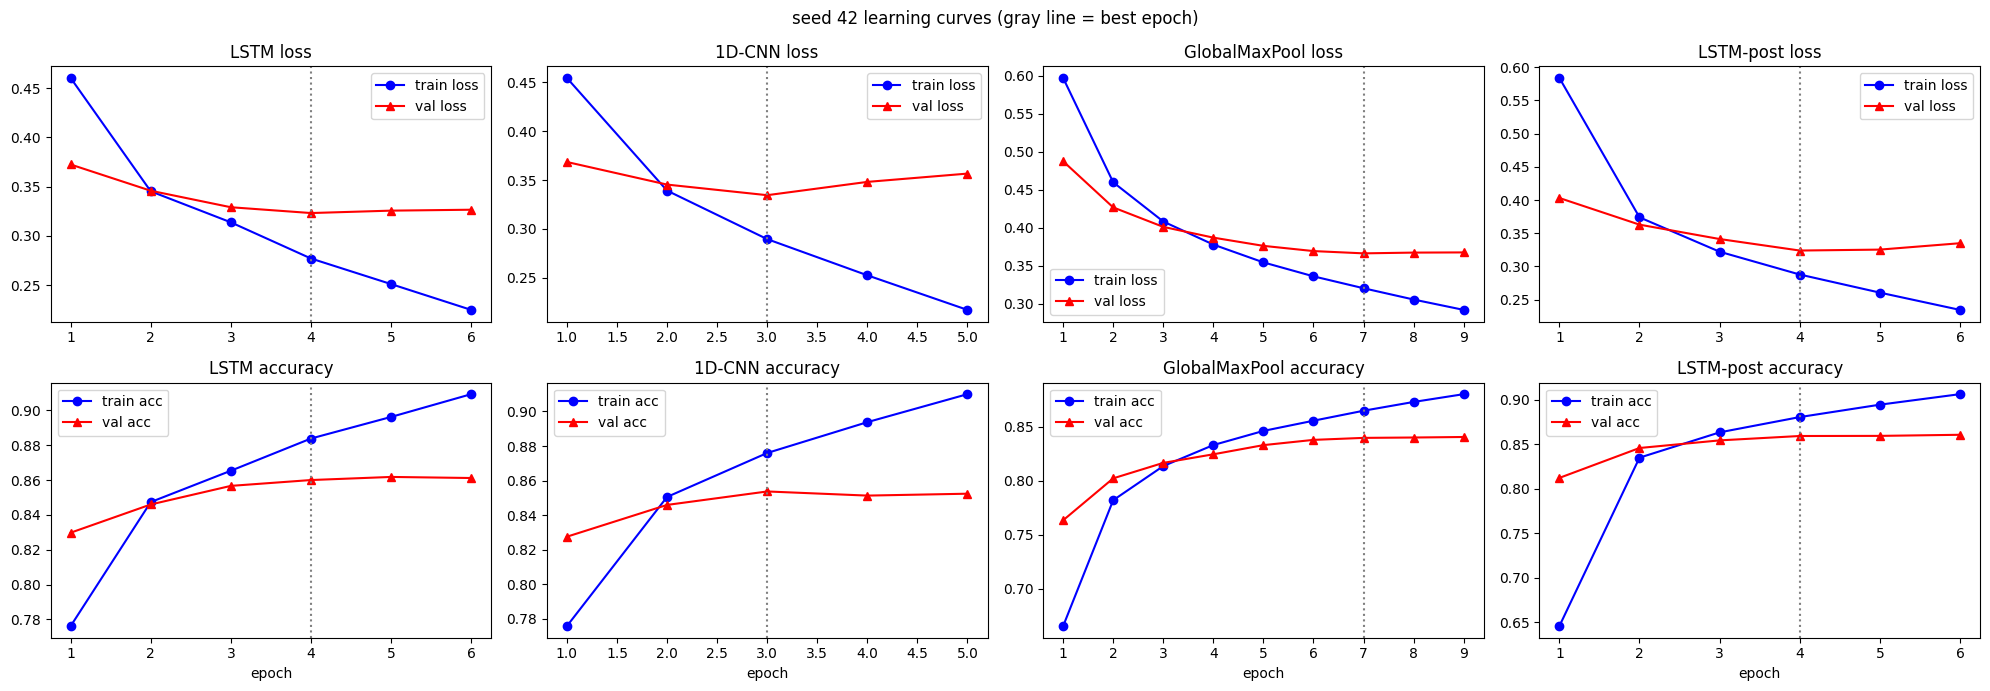

In [23]:
def plot_histories(hist_dict, title=''):
    fig, axes = plt.subplots(2, len(hist_dict), figsize=(5 * len(hist_dict), 7), squeeze=False)
    for col, (name, r) in enumerate(hist_dict.items()):
        h = r['history']; ep = range(1, len(h['train_loss']) + 1)
        axes[0, col].plot(ep, h['train_loss'], 'bo-', label='train loss')
        axes[0, col].plot(ep, h['val_loss'], 'r^-', label='val loss')
        axes[0, col].axvline(r['best_epoch'], color='gray', linestyle=':')
        axes[0, col].set_title(f'{name} loss'); axes[0, col].legend()
        axes[1, col].plot(ep, h['train_acc'], 'bo-', label='train acc')
        axes[1, col].plot(ep, h['val_acc'], 'r^-', label='val acc')
        axes[1, col].axvline(r['best_epoch'], color='gray', linestyle=':')
        axes[1, col].set_title(f'{name} accuracy'); axes[1, col].set_xlabel('epoch'); axes[1, col].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_histories({n: all_runs[n][SEEDS[0]] for n in ['LSTM', '1D-CNN', 'GlobalMaxPool', 'LSTM-post']},
               f'seed {SEEDS[0]} learning curves (gray line = best epoch)')

seed 42 기준으로 보면 train loss는 계속 내려가는데 val loss는 LSTM 4 epoch, 1D-CNN 3 epoch, LSTM-post 4 epoch에서 가장 낮고 그 뒤로 다시 올라간다. 그 뒤로는 train 정확도만 오르고 val 정확도는 거의 그대로여서 이 지점부터를 과적합으로 보고, val loss가 가장 낮은 epoch(회색 점선)의 가중치를 썼다.

- 1D-CNN은 LSTM보다 1 epoch 빨리 과적합이 시작되고, 그 뒤 val loss가 더 가파르게 오른다(3 epoch 0.3345 → 5 epoch 0.3566).
- GlobalMaxPool은 같은 epoch에서 train 정확도 자체가 가장 낮고, val loss가 7 epoch까지 천천히 내려간다. 다른 seed에서는 best epoch가 9와 10이었는데 10은 설정한 최대 epoch라서, 이 모델은 10 epoch 안에 완전히 수렴하지 못했을 수 있다. 임베딩을 뺀 파라미터가 6천 개뿐이고 단어 순서도 쓰지 않으니 과적합보다는 표현력이 부족한 쪽으로 봤다.
- LSTM-post는 1 epoch val 정확도가 81.2%로 pre(83.0%)보다 느리게 출발했지만 4 epoch에서는 85.9%로 비슷해졌다. 문장 뒤에 패딩이 붙어도 LSTM이 패딩 구간에서는 상태를 크게 바꾸지 않도록 학습됐기 때문일 수 있는데, gate 값을 직접 확인하지는 않았다.

In [24]:
def summarize(names, show_baseline=True):
    print(f'{"model":<22}{"best ep":>9}{"val acc (%)":>17}{"test acc (%)":>17}')
    for n in names:
        runs = all_runs[n].values()
        ep = np.mean([r['best_epoch'] for r in runs])
        va = np.array([r['val_acc'] for r in runs]) * 100
        te = np.array([r['test_acc'] for r in runs]) * 100
        print(f'{n:<22}{ep:>9.1f}{va.mean():>10.2f} ± {va.std(ddof=1):.2f}{te.mean():>10.2f} ± {te.std(ddof=1):.2f}')
    if show_baseline:
        print(f'{"TF-IDF + LogReg":<22}{"-":>9}{baseline["val_acc"]*100:>10.2f}{"":>7}{baseline["test_acc"]*100:>10.2f}')
    print(f'(신경망은 seed {SEEDS} 3회 평균 ± 표준편차, TF-IDF는 결정적이라 1회)')

summarize(['LSTM', '1D-CNN', 'GlobalMaxPool', 'LSTM-post'])

model                   best ep      val acc (%)     test acc (%)
LSTM                        4.0     85.97 ± 0.05     85.75 ± 0.04
1D-CNN                      3.0     85.49 ± 0.17     85.18 ± 0.10
GlobalMaxPool               8.7     83.79 ± 0.17     83.35 ± 0.24
LSTM-post                   4.3     86.13 ± 0.25     85.64 ± 0.28
TF-IDF + LogReg               -     86.91            86.85
(신경망은 seed [42, 43, 44] 3회 평균 ± 표준편차, TF-IDF는 결정적이라 1회)


3번 반복한 평균으로 보면 신경망 중에서는 LSTM(test 85.75 ± 0.04%)이 1D-CNN(85.18 ± 0.10%)보다 높고 GlobalMaxPool(83.35 ± 0.24%)이 가장 낮다. LSTM과 1D-CNN의 차이(0.57%p)는 seed 사이 표준편차보다 몇 배 커서 우연으로 보기 어렵다.

RQ2(padding 방향): val에서는 post가 0.16%p 높고 test에서는 pre가 0.11%p 높아서 방향이 일정하지 않고, 둘 다 표준편차(최대 0.28%p) 안이다. 그래서 NSMC에서는 padding 방향에 따른 차이가 없다고 정리했다. 노드의 IMDB 예시는 maxlen이 580이었는데 여기서는 41이라 패딩 구간이 짧은 것이 이유로 보인다.

예상과 달랐던 것은 비교 기준으로 둔 TF-IDF + 로지스틱 회귀가 test 86.85%로 이 표의 모든 신경망보다 높았다는 점이다. 리뷰가 짧고 '재미 없', '최고 영화'처럼 두 단어 조합만으로도 극성이 상당 부분 드러나서 bigram 선형 모델이 강한 것 같다. 같은 사전과 같은 토큰을 쓰고 있어서 전처리 차이로 생긴 결과는 아니다. 다만 TF-IDF는 C를 validation으로 4개 중에서 골랐고 신경망은 한 가지 설정으로만 학습했기 때문에, 튜닝 정도가 같지 않다는 점은 감안해야 한다.

## 7) 학습된 Embedding 레이어 분석
---

In [25]:
# seed 42 LSTM(랜덤 초기화)에서 학습된 임베딩을 word2vec 텍스트 형식으로 저장한 뒤 gensim으로 읽는다.
os.makedirs('/content/sentiment_classification/data', exist_ok=True)
my_vec_path = '/content/sentiment_classification/data/word2vec_nsmc_lstm.txt'
vectors = all_runs['LSTM'][SEEDS[0]]['model'].embedding.weight.detach().cpu().numpy()
with open(my_vec_path, 'w') as f:
    f.write(f'{vocab_size - 4} {word_vector_dim}\n')
    for i in range(4, vocab_size):
        f.write(index_to_word[i] + ' ' + ' '.join(map(str, vectors[i])) + '\n')
my_vectors = KeyedVectors.load_word2vec_format(my_vec_path, binary=False)

def show_similar(word, topn=8):
    mine = [f'{w}({s:.2f})' for w, s in my_vectors.most_similar(word, topn=topn)] if word in my_vectors else ['사전에 없음']
    pre = [f'{w}({s:.2f})' for w, s in w2v.most_similar(word, topn=topn)] if word in w2v else ['사전에 없음']
    print(f'■ {word}')
    print('  자체학습 :', ', '.join(mine))
    print('  word2vec :', ', '.join(pre))

for word in ['재미', '최고', '감동', '지루', '쓰레기', '배우', '연기', '스토리']:
    show_similar(word)

■ 재미
  자체학습 : 모시(0.35), 특촬물(0.35), 관객(0.34), 평온(0.32), 기법(0.32), 라서(0.32), 시련(0.32), 두근거리(0.31)
  word2vec : 묘미(0.62), 취미(0.60), 흥미(0.59), 유머(0.59), 보람(0.57), 즐거움(0.56), 개그(0.56), 이야기(0.55)
■ 최고
  자체학습 : 설명(0.38), 남아도(0.35), 낙(0.35), 웨폰(0.33), 3500(0.33), 강우석(0.33), 상위(0.33), 사(0.32)
  word2vec : 역대(0.65), 최다(0.61), 최악(0.61), 최대(0.60), 최저(0.59), 정상급(0.59), 올해(0.58), 우수(0.57)
■ 감동
  자체학습 : 넘어가(0.37), 심은경(0.36), 넘길(0.35), 충만(0.35), 가만히(0.34), 냉소(0.33), 장국영(0.33), 삽입곡(0.32)
  word2vec : 감격(0.80), 감탄(0.73), 매혹(0.73), 매력(0.71), 감명(0.71), 웃음(0.70), 열정(0.69), 칭찬(0.68)
■ 지루
  자체학습 : 욕(0.36), 몰락(0.35), 짐작(0.35), 한숨(0.35), 류영화(0.34), 연쇄(0.33), 스티(0.33), 못생김(0.33)
  word2vec : 답답(0.84), 불쾌(0.84), 지저분(0.83), 조용(0.83), 피곤(0.82), 쓸쓸(0.81), 어색(0.81), 침울(0.81)
■ 쓰레기
  자체학습 : 에러(0.40), 잘라(0.36), 베트(0.35), 나와요(0.35), 인주(0.33), 고소영(0.33), 부재(0.32), 웩(0.32)
  word2vec : 폐수(0.77), 폐기물(0.76), 지하수(0.69), 식수(0.69), 더미(0.69), 분뇨(0.68), 소각장(0.68), 하수(0.68)
■ 배우
  자체학습 : 우익(0.38), 밋기(0.36), 엉성(0.35), 돋보이(0.34), 

이웃 단어 목록만으로는 인상 비교에 그치기 때문에, 긍정 단어 묶음과 부정 단어 묶음이 임베딩 공간에서 얼마나 갈라져 있는지를 코사인 유사도로 수치화했다. 같은 극성끼리의 평균 유사도(within)에서 반대 극성 사이의 평균 유사도(between)를 뺀 값을 극성 분리도로 정의했다. 값이 클수록 긍정과 부정 단어가 따로 모여 있다는 뜻이다.

In [26]:
pos_words = ['최고', '감동', '재미', '추천', '명작', '훌륭', '재밌', '좋']
neg_words = ['최악', '지루', '쓰레기', '실망', '별로', '짜증', '아깝', '유치']
pos_words = [w for w in pos_words if w in word_to_index and w in w2v]
neg_words = [w for w in neg_words if w in word_to_index and w in w2v]
print('사용한 단어  긍정:', pos_words, ' 부정:', neg_words)

def polarity_separation(vec):
    """vec(word) -> 벡터. 같은 극성 쌍의 평균 코사인 - 반대 극성 쌍의 평균 코사인"""
    unit = lambda v: v / np.linalg.norm(v)
    P = np.stack([unit(vec(w)) for w in pos_words]); N = np.stack([unit(vec(w)) for w in neg_words])
    within_p = (P @ P.T)[np.triu_indices(len(P), 1)].mean()
    within_n = (N @ N.T)[np.triu_indices(len(N), 1)].mean()
    between = (P @ N.T).mean()
    return (within_p + within_n) / 2, between, (within_p + within_n) / 2 - between

def emb_of(model):
    W = model.embedding.weight.detach().cpu().numpy()
    return lambda w: W[word_to_index[w]]

sep_rows = [('word2vec_ko (원본)', polarity_separation(lambda w: w2v[w]))]
for seed in SEEDS:
    sep_rows.append((f'자체학습 LSTM seed {seed}', polarity_separation(emb_of(all_runs['LSTM'][seed]['model']))))
print(f'{"embedding":<24}{"within":>8}{"between":>9}{"분리도":>8}')
for name, (wi, be, sep) in sep_rows:
    print(f'{name:<24}{wi:>8.3f}{be:>9.3f}{sep:>8.3f}')

사용한 단어  긍정: ['최고', '감동', '재미', '추천', '명작', '훌륭', '재밌', '좋']  부정: ['최악', '지루', '쓰레기', '실망', '별로', '짜증', '아깝', '유치']
embedding                 within  between     분리도
word2vec_ko (원본)           0.241    0.223   0.017
자체학습 LSTM seed 42          0.069   -0.033   0.103
자체학습 LSTM seed 43          0.089   -0.067   0.156
자체학습 LSTM seed 44          0.043    0.004   0.039


자체 학습한 임베딩은 이웃 단어의 유사도가 0.3에서 0.4 정도로 낮고, '재미' 옆에 '모시', '특촬물', '최고' 옆에 '설명', '웨폰'처럼 의미 관계가 없는 단어들이 나왔다. word2vec_ko는 '재미 → 묘미, 흥미, 즐거움', '배우 → 영화배우, 여배우', '스토리 → 줄거리, 시나리오'처럼 뜻이 가까운 단어를 잘 찾는다.

그런데 극성 분리도로 보면 결과가 반대다. word2vec_ko는 0.017로 긍정 단어와 부정 단어가 거의 섞여 있고(같은 극성 0.241, 반대 극성 0.223), 자체 학습 임베딩은 seed에 따라 0.039에서 0.156으로 값은 흔들리지만 세 번 모두 word2vec보다 컸다. 자체 학습 임베딩은 단어의 뜻은 거의 배우지 못했지만 긍정/부정 방향은 조금 배웠고, word2vec_ko는 뜻은 잘 담고 있지만 감성 극성은 거의 구분하지 못한다고 정리할 수 있다.

이웃 단어에서도 같은 문제가 보인다. '최고'의 이웃에 '최악'이 있고, '쓰레기'의 이웃은 '폐수, 폐기물, 분뇨'처럼 리뷰에서 쓰는 욕의 의미가 아니라 사전적인 의미다. word2vec은 주변 문맥이 비슷한 단어를 가깝게 두기 때문에 반대 극성의 단어도 가까워질 수 있고, 리뷰가 아닌 일반 문서로 학습된 벡터라 도메인 차이도 있는 것 같다. 단어 16개로 계산한 값이라 분리도의 크기 자체보다는 word2vec과 자체 학습 임베딩 사이의 차이 방향 정도로만 해석했다.

## 8) 한국어 Word2Vec 임베딩 활용하여 성능 개선
---
- 한국어 Word2Vec은 /data 폴더 안에 있는 word2vec_ko.model을 활용하세요.
- 한국어 Word2Vec을 활용할 때는 `load_word2vec_format()` 형태가 아닌 `load()` 형태로 모델을 불러와주세요. 또한 모델을 활용할 때에는 아래 예시와 같이 `.wv`를 붙여서 활용합니다. 좀더 자세한 활용법에 대해선 다음 링크들을 참조해주세요. [참고 링크1](https://radimrehurek.com/gensim/auto_examples/tutorials/run_word2vec.html#storing-and-loading-models), [참고 링크2](https://radimrehurek.com/gensim/models/keyedvectors.html)



```
# 예시 코드
from gensim.models.keyedvectors import Word2VecKeyedVectors
word_vectors = Word2VecKeyedVectors.load(word2vec_file_path)
vector = word_vectors.wv[‘끝’]
```



In [27]:
# 사전 단어마다 word2vec_ko 벡터를 복사한다. 없는 단어는 word2vec 벡터의 분포에 맞춘 랜덤값으로 둔다.
rng = np.random.default_rng(0)
embedding_matrix = rng.normal(0, w2v.vectors.std(), size=(vocab_size, word_vector_dim)).astype(np.float32)
embedding_matrix[0] = 0  # <PAD>
found = 0
for i in range(4, vocab_size):
    if index_to_word[i] in w2v:
        embedding_matrix[i] = w2v[index_to_word[i]]
        found += 1
print(f'사전 {vocab_size - 4}개 단어 중 word2vec_ko에 있는 단어: {found}개 ({found / (vocab_size - 4):.2%})')
missing = [index_to_word[i] for i in range(4, vocab_size) if index_to_word[i] not in w2v]
print('word2vec에 없는 단어 예 (빈도순):', missing[:20])
miss_ids = {word_to_index[w] for w in missing}
print('test 문장 중 word2vec에 없는 단어가 하나 이상 있는 비율: {:.4f}'.format(np.mean([any(t in miss_ids for t in s) for s in X_test])))

사전 9996개 단어 중 word2vec_ko에 있는 단어: 9435개 (94.39%)
word2vec에 없는 단어 예 (빈도순): ['ㅠㅠ', '....', 'ㅜㅜ', 'ㅋㅋㅋㅋ', '강추', '~~~', ';;;', '.....', 'ㅉㅉ', '아까움', '-_-', '네여', '왠만', '별루', 'ㅠㅠㅠ', 'ㅋㅋㅋㅋㅋ', '봣는데', '......', '낚였', '~~~~']
test 문장 중 word2vec에 없는 단어가 하나 이상 있는 비율: 0.1408


RQ3를 보기 위해 LSTM 구조와 하이퍼파라미터를 그대로 두고 임베딩만 바꾼 두 설정을 추가했다. `LSTM+w2v(fine-tune)`은 word2vec_ko로 초기화한 뒤 임베딩도 같이 학습하고, `LSTM+w2v(frozen)`은 임베딩을 고정한 채 LSTM과 분류층만 학습한다.

In [28]:
run_config('LSTM+w2v(fine-tune)', lambda: LSTMClassifier(vocab_size, word_vector_dim, embedding_matrix=embedding_matrix), loaders_pre)
run_config('LSTM+w2v(frozen)', lambda: LSTMClassifier(vocab_size, word_vector_dim, embedding_matrix=embedding_matrix, freeze_embedding=True), loaders_pre)

[LSTM+w2v(fine-tune)/seed42] epoch  1 | train loss 0.4440 acc 0.7901 | val loss 0.3495 acc 0.8463
[LSTM+w2v(fine-tune)/seed42] epoch  2 | train loss 0.3273 acc 0.8589 | val loss 0.3268 acc 0.8583
[LSTM+w2v(fine-tune)/seed42] epoch  3 | train loss 0.2870 acc 0.8785 | val loss 0.3088 acc 0.8659
[LSTM+w2v(fine-tune)/seed42] epoch  4 | train loss 0.2597 acc 0.8919 | val loss 0.3116 acc 0.8678
[LSTM+w2v(fine-tune)/seed42] epoch  5 | train loss 0.2354 acc 0.9034 | val loss 0.3093 acc 0.8673
  LSTM+w2v(fine-tune) seed 42: best epoch 3, val acc 0.8659
  LSTM+w2v(fine-tune) seed 43: best epoch 4, val acc 0.8682
  LSTM+w2v(fine-tune) seed 44: best epoch 4, val acc 0.8670
  (70s)
[LSTM+w2v(frozen)/seed42] epoch  1 | train loss 0.4748 acc 0.7702 | val loss 0.3948 acc 0.8189
[LSTM+w2v(frozen)/seed42] epoch  2 | train loss 0.3827 acc 0.8274 | val loss 0.3666 acc 0.8353
[LSTM+w2v(frozen)/seed42] epoch  3 | train loss 0.3480 acc 0.8453 | val loss 0.3630 acc 0.8371
[LSTM+w2v(frozen)/seed42] epoch  4 | 

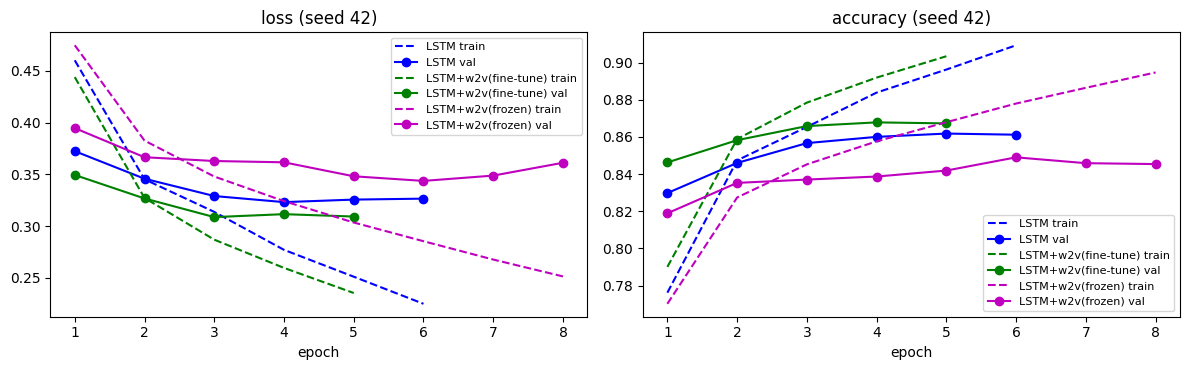

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, style in [('LSTM', 'b'), ('LSTM+w2v(fine-tune)', 'g'), ('LSTM+w2v(frozen)', 'm')]:
    h = all_runs[name][SEEDS[0]]['history']; ep = range(1, len(h['val_loss']) + 1)
    axes[0].plot(ep, h['train_loss'], style + '--', label=f'{name} train')
    axes[0].plot(ep, h['val_loss'], style + '-o', label=f'{name} val')
    axes[1].plot(ep, h['train_acc'], style + '--', label=f'{name} train')
    axes[1].plot(ep, h['val_acc'], style + '-o', label=f'{name} val')
axes[0].set_title(f'loss (seed {SEEDS[0]})'); axes[1].set_title(f'accuracy (seed {SEEDS[0]})')
for ax in axes: ax.set_xlabel('epoch'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

seed 42에서 word2vec으로 초기화하고 같이 학습한 LSTM(fine-tune)은 1 epoch부터 val 정확도가 84.6%로 랜덤 초기화(83.0%)보다 높게 시작했고, val loss도 모든 epoch에서 더 낮았다(최저 0.3088, 랜덤 초기화 0.3233). 다만 train 정확도는 계속 오르는데 val은 86.6에서 86.8% 근처에서 멈추는 과적합 패턴은 같아서, 사전학습 임베딩이 과적합을 줄였다기보다는 더 좋은 지점에서 출발하게 해 준 것으로 보인다.

임베딩을 고정한(frozen) 경우는 오히려 랜덤 초기화보다 낮게 시작했고(1 epoch 81.9%) 6 epoch까지 천천히 올라 84.9%에서 멈췄다. 임베딩을 학습할 수 없으니 극성을 거의 구분하지 못하는 word2vec 공간을 LSTM이 그대로 받아야 하고, word2vec에 없는 'ㅋㅋㅋㅋ', '강추' 같은 단어는 랜덤 벡터로 고정된 채 남는다. 이런 단어가 하나라도 들어간 test 문장이 14.1%였다.

In [30]:
from scipy.stats import chi2

summarize(['LSTM', '1D-CNN', 'GlobalMaxPool', 'LSTM-post', 'LSTM+w2v(fine-tune)', 'LSTM+w2v(frozen)'])

# 같은 seed끼리 test 예측을 짝지어 McNemar 검정 (연속성 보정)
print('\nMcNemar: LSTM vs LSTM+w2v(fine-tune)')
for seed in SEEDS:
    a = (all_runs['LSTM'][seed]['test_proba'] > 0.5) == y_test
    b = (all_runs['LSTM+w2v(fine-tune)'][seed]['test_proba'] > 0.5) == y_test
    n01, n10 = np.sum(a & ~b), np.sum(~a & b)   # LSTM만 맞힘 / w2v만 맞힘
    stat = (abs(n01 - n10) - 1) ** 2 / (n01 + n10)
    print(f'  seed {seed}: LSTM만 맞힘 {n01}, w2v만 맞힘 {n10}, 정확도 차 {(b.mean() - a.mean()) * 100:+.2f}%p, p = {chi2.sf(stat, 1):.2e}')

# 학습이 끝난 뒤 극성 분리도와 이웃 단어 변화
tuned = all_runs['LSTM+w2v(fine-tune)'][SEEDS[0]]['model']
print('\n극성 분리도  word2vec 원본 {:.3f} → fine-tune 후 {:.3f}'.format(polarity_separation(lambda w: w2v[w])[2], polarity_separation(emb_of(tuned))[2]))
tuned_vectors = KeyedVectors(vector_size=word_vector_dim)
tuned_vectors.add_vectors([index_to_word[i] for i in range(4, vocab_size)], tuned.embedding.weight.detach().cpu().numpy()[4:])
for word in ['재미', '최고', '지루']:
    print(word, '→', [w for w, _ in tuned_vectors.most_similar(word, topn=8)])

model                   best ep      val acc (%)     test acc (%)
LSTM                        4.0     85.97 ± 0.05     85.75 ± 0.04
1D-CNN                      3.0     85.49 ± 0.17     85.18 ± 0.10
GlobalMaxPool               8.7     83.79 ± 0.17     83.35 ± 0.24
LSTM-post                   4.3     86.13 ± 0.25     85.64 ± 0.28
LSTM+w2v(fine-tune)         3.7     86.70 ± 0.12     86.51 ± 0.11
LSTM+w2v(frozen)            5.0     84.52 ± 0.34     84.17 ± 0.24
TF-IDF + LogReg               -     86.91            86.85
(신경망은 seed [42, 43, 44] 3회 평균 ± 표준편차, TF-IDF는 결정적이라 1회)

McNemar: LSTM vs LSTM+w2v(fine-tune)
  seed 42: LSTM만 맞힘 2054, w2v만 맞힘 2418, 정확도 차 +0.74%p, p = 5.69e-08
  seed 43: LSTM만 맞힘 1899, w2v만 맞힘 2327, 정확도 차 +0.87%p, p = 5.08e-11
  seed 44: LSTM만 맞힘 2136, w2v만 맞힘 2472, 정확도 차 +0.68%p, p = 8.01e-07

극성 분리도  word2vec 원본 0.017 → fine-tune 후 0.104
재미 → ['묘미', '취미', '유머', '흥미', '보람', '즐거움', '개그', '공감']
최고 → ['역대', '최대', '올해', '우수', '최저', '최악', '최초', '최강']
지루 → ['답답', '불쾌', '어색', '

RQ3: word2vec_ko로 초기화하고 같이 학습하면 test 86.51 ± 0.11%로 랜덤 초기화 LSTM(85.75 ± 0.04%)보다 0.76%p 높았다. 같은 seed끼리 test 문장 49,157개의 예측을 짝지어 McNemar 검정을 하면 세 seed 모두 p < 1e-6이었고, seed별 차이는 0.68에서 0.87%p였다. 차이는 작지만 seed나 우연으로 설명되는 수준은 아니다.

반대로 임베딩을 고정하면 84.17 ± 0.24%로 랜덤 초기화보다 1.6%p 낮아졌다. word2vec_ko는 그대로 특성으로 쓸 때는 도움이 안 되고, 초기값으로 쓰고 감성 데이터로 다시 학습할 때만 도움이 됐다. fine-tune 후 극성 분리도가 0.017에서 0.104로 올라간 것도 같은 방향이다. 학습하면서 긍정과 부정 단어가 갈라지는 쪽으로 임베딩이 움직였다. 그래도 '최고'의 이웃에는 여전히 '최악'이 남아 있어서, 4 epoch 정도의 학습으로는 word2vec의 원래 구조가 대부분 유지된다.

노드에서는 Word2Vec을 쓰면 5% 이상 오른다고 했지만 여기서는 0.76%p였다. 학습 데이터가 13만 개로 많아서 랜덤 초기화로도 임베딩을 꽤 학습할 수 있고, word2vec_ko 자체가 극성 정보를 거의 담고 있지 않기 때문이라고 본다. 이 모델(86.51%)도 TF-IDF + 로지스틱 회귀(86.85%)를 넘지는 못했다.

## 9) 오류 분석
---
신경망 중 validation 평균 정확도가 가장 높은 설정의 seed 42 모델로 test 오답을 살펴봤다. 문장 길이에 따라 정확도가 어떻게 달라지는지, 특히 maxlen에서 잘린 문장이 불리한지와 어떤 문장을 확신을 갖고 틀리는지를 확인했다.

분석 모델: LSTM+w2v(fine-tune) (seed 42)
confusion matrix (행: 정답 부정/긍정, 열: 예측 부정/긍정)
 [[21604  2842]
 [ 3821 20890]]
부정 recall 0.8837, 긍정 recall 0.8454
  토큰 0-5                6516문장  정확도 0.8576
  토큰 6-10              14449문장  정확도 0.8570
  토큰 11-20             17340문장  정확도 0.8639
  토큰 21-41              7652문장  정확도 0.8866
  토큰 42+ (truncated)    3200문장  정확도 0.8622


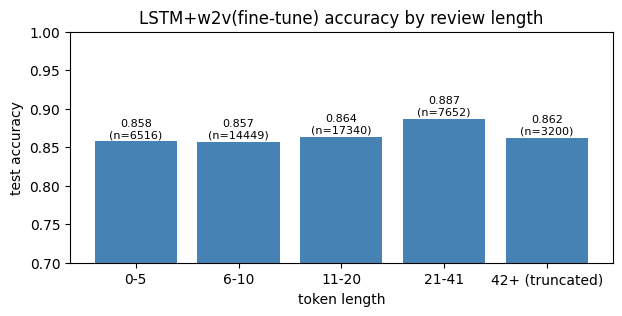

In [31]:
from sklearn.metrics import confusion_matrix

best_name = max(all_runs, key=lambda n: np.mean([r['val_acc'] for r in all_runs[n].values()]))
proba = all_runs[best_name][SEEDS[0]]['test_proba']
pred = (proba > 0.5).astype(int)
print('분석 모델:', best_name, f'(seed {SEEDS[0]})')
cm = confusion_matrix(y_test, pred)
print('confusion matrix (행: 정답 부정/긍정, 열: 예측 부정/긍정)\n', cm)
print('부정 recall {:.4f}, 긍정 recall {:.4f}'.format(cm[0, 0] / cm[0].sum(), cm[1, 1] / cm[1].sum()))

test_len = np.array([len(s) for s in X_test])
bins = [(0, 5), (6, 10), (11, 20), (21, maxlen), (maxlen + 1, 10**6)]
labels, accs, counts = [], [], []
for lo, hi in bins:
    m = (test_len >= lo) & (test_len <= hi)
    labels.append(f'{lo}-{hi}' if hi < 10**6 else f'{lo}+ (truncated)')
    accs.append(np.mean(pred[m] == y_test[m])); counts.append(m.sum())
for l, a, c in zip(labels, accs, counts):
    print(f'  토큰 {l:<16} {c:>6}문장  정확도 {a:.4f}')

plt.figure(figsize=(7, 3))
plt.bar(labels, accs, color='steelblue')
for i, (a, c) in enumerate(zip(accs, counts)):
    plt.text(i, a + 0.005, f'{a:.3f}\n(n={c})', ha='center', fontsize=8)
plt.ylim(0.7, 1.0); plt.ylabel('test accuracy'); plt.xlabel('token length')
plt.title(f'{best_name} accuracy by review length')
plt.show()

오류 분석은 신경망 중 val 평균이 가장 높은 LSTM+w2v(fine-tune)의 seed 42 모델로 했다. 부정 리뷰 recall은 88.4%, 긍정 리뷰 recall은 84.5%로, 긍정 리뷰를 부정으로 틀린 경우(3,821개)가 반대 경우(2,842개)보다 1천 개 가까이 많다. test의 긍정 비율이 50.3%로 거의 균형이라 데이터 불균형 때문은 아니고, 모델이 애매한 리뷰를 부정 쪽으로 판단하는 경향이 있다.

길이별로는 21에서 41토큰 문장이 88.7%로 가장 잘 맞고, 10토큰 이하의 짧은 문장이 85.7에서 85.8%로 가장 낮다. 짧은 리뷰는 판단할 단서가 적어서 어렵다. maxlen 41에서 잘린 42토큰 이상 문장(3,200개)은 86.2%로 21에서 41 구간보다 2.4%p 낮아서, 잘린 뒷부분에 정보가 일부 있었던 것으로 보인다. 다만 test의 6.5%뿐이라 maxlen을 늘려도 전체 정확도는 많아야 0.2%p 정도 오를 것 같다.

In [32]:
# 확신을 갖고 틀린 문장 (예측 확률이 0이나 1에 가까운데 틀린 경우)
wrong = np.where(pred != y_test)[0]
conf = np.abs(proba[wrong] - 0.5)
for i in wrong[np.argsort(-conf)][:10]:
    print(f'정답 {y_test[i]} / 긍정 확률 {proba[i]:.3f} | {test_docs[i]}')

정답 0 / 긍정 확률 0.998 | 와 이거 대박!너무 재밌는거 아냐!!!강추~ 강추!소장용으로 강추!연인과함께 강추!
정답 0 / 긍정 확률 0.997 | 재미는 없지만 독특한 매력이 있는 영화가장 기억에 남는 건 남여주인공이 서로 만난 순간 나눈 스킨쉽 장면 이었다. 음악과 달듯 말듯한 그들의 몸짓과 손짓이 신비로웠다. 무섭고 슬픈영화였다..
정답 0 / 긍정 확률 0.997 | 굿긋굿긋굿긋굿긋굿긋굿
정답 1 / 긍정 확률 0.003 | 별로다루지않았던 참신한소재 연기도 괜찮음 하지만 소현세자 죽이기 까지너무 질질끌음.
정답 1 / 긍정 확률 0.003 | 이영화가 남겨준의미가 도대체뭔지 한번 물어나보자라니?? 볼줄모르면 그냥 영화를보지말지 잘만들어논영화를 1점주고 어휴 수준이하
정답 1 / 긍정 확률 0.003 | 포켓몬스터 시리즈중 1기.2기가 가장 재밌다 나머진 다 스토리도 별로고 너무 재미없음..
정답 1 / 긍정 확률 0.003 | 그래픽티 나는 괴물 허술한 스토리 허무한 결말 어색한 연기
정답 1 / 긍정 확률 0.004 | 그냥 뮤직비디오 본다고 생각하면 훌륭한 작품이다. 동양인 비하라고 하는 분들에게 몇마디하자면 이 영화 자체가 디스를 통한 개그코드를 유지합니다. 남녀 비하, 유태인, 레즈비언, 오타쿠들 등등 동양인도 그소재중 하나지 동양비하가 본 목적은 아니에요 ㅋㅋ
정답 1 / 긍정 확률 0.004 | 재미없다.잘키운 딸하나 많은 시청보지마세요.
정답 1 / 긍정 확률 0.004 | 밑에분말대로 진행이 너무지루하다...그게좀아쉽다


확신을 갖고 틀린 10개를 직접 읽고 나눠 봤다(번호는 위에서부터).

- 글의 내용과 라벨이 반대로 보이는 경우 4개(1, 3, 7, 9번). 1번은 '강추'를 네 번 쓴 리뷰인데 라벨이 부정이고, 7번은 '허술한 스토리 허무한 결말 어색한 연기'인데 라벨이 긍정이다. NSMC 라벨은 사용자가 준 평점으로 정해지기 때문에 글과 평점이 어긋난 리뷰가 섞여 있는 것 같다. 이런 문장은 모델이 맞히기 어렵고, 이 데이터에서 얻을 수 있는 정확도의 상한을 낮춘다.
- 다른 사람의 평가나 다른 작품을 비판하는 표현이 섞인 경우 3개(5, 6, 8번). 5번은 1점 준 다른 사람들을 '수준이하'라고 비판하는 긍정 리뷰인데, 부정 단어가 많아서 부정으로 판단했다. 무엇을 비판하는지까지는 모델이 구분하지 못한다.
- 장점과 단점이 같이 있는 경우 2개(2, 10번).
- '별로다루지않았던'(많이 다뤄지지 않았던)처럼 감성과 상관없이 쓰인 '별로'가 부정 단서로 작용한 것으로 보이는 경우 1개(4번).

10개만 본 것이라 비율을 일반화할 수는 없지만, 확신을 갖고 틀린 오류 중 상당수는 모델 구조보다 라벨 잡음이나 문맥 이해의 문제로 보인다.

## 결론

| 설정 | val acc (%) | test acc (%) |
|---|---|---|
| TF-IDF + LogReg | 86.91 | 86.85 |
| LSTM + word2vec_ko (fine-tune) | 86.70 ± 0.12 | 86.51 ± 0.11 |
| LSTM-post | 86.13 ± 0.25 | 85.64 ± 0.28 |
| LSTM | 85.97 ± 0.05 | 85.75 ± 0.04 |
| 1D-CNN | 85.49 ± 0.17 | 85.18 ± 0.10 |
| LSTM + word2vec_ko (frozen) | 84.52 ± 0.34 | 84.17 ± 0.24 |
| GlobalMaxPool | 83.79 ± 0.17 | 83.35 ± 0.24 |

(신경망은 seed 3개의 평균 ± 표준편차, TF-IDF는 1회)

- RQ1: 같은 조건에서 LSTM > 1D-CNN > GlobalMaxPool 순이었고 차이는 seed 편차보다 컸다. 하지만 TF-IDF + 로지스틱 회귀가 모든 신경망보다 높아서, 짧은 리뷰가 많은 NSMC에서는 단어 조합만으로도 많은 부분을 맞힐 수 있었다. 신경망은 한 가지 설정으로만 학습했으므로 '신경망이 선형 모델보다 못하다'가 아니라 '이 설정의 신경망은 선형 모델보다 낫지 않았다'까지만 말할 수 있다.
- RQ2: pre와 post padding은 차이가 없었다(방향이 일정하지 않고 표준편차 안).
- RQ3: word2vec_ko로 초기화하고 같이 학습하면 0.76%p로 작지만 통계적으로 유의하게 올랐고(McNemar p < 1e-6), 고정하면 오히려 1.6%p 떨어졌다. word2vec_ko는 단어의 뜻은 잘 담고 있지만 감성 극성은 거의 구분하지 못해서(극성 분리도 0.017), 감성 데이터로 다시 학습할 때만 도움이 된다.

루브릭 기준인 정확도 85% 이상은 LSTM, LSTM-post, 1D-CNN, LSTM + word2vec_ko(fine-tune)가 넘었다. 모델과 epoch 선택은 모두 validation으로 했고, test 결과를 본 뒤 설정을 바꾸지 않았다. 다만 모든 설정을 같은 test로 비교했기 때문에 이 표에서 test가 가장 높은 설정을 최종 모델로 고르면 test를 선택에 쓴 셈이 된다. 신경망 중에서는 val 기준으로도 LSTM + word2vec_ko(fine-tune)가 가장 높다.

## 회고 (KPT)

### Keep
- 연구 질문 세 개를 먼저 정하고 비교할 때 바꾸는 조건을 하나로 제한했습니다. 그래서 frozen과 fine-tune 비교처럼 word2vec이 왜 도움이 되는지까지 나눠서 볼 수 있었습니다.
- seed 3개 반복과 McNemar 검정으로 0.76%p라는 작은 차이가 우연이 아닌지 확인했습니다. 반대로 pre와 post의 차이는 seed 편차 안이라 차이가 없다고 정리했습니다.
- 신경망끼리만 비교하지 않고 TF-IDF + 로지스틱 회귀를 기준으로 둔 덕분에, 이 설정의 신경망이 선형 모델보다 낫지 않다는 결과를 놓치지 않았습니다.
- 에러 없이 돌아가는 원본 코드도 사전을 직접 확인해서 `load_data`의 특수 토큰 버그를 찾았습니다.

### Problem
- 신경망은 한 가지 설정(임베딩 100, hidden 128, lr 1e-3)으로만 학습했고 TF-IDF는 C를 validation으로 골라서, 두 방식의 튜닝 정도가 같지 않습니다.
- 사전 10,000개 때문에 test 문장의 41.5%에 <UNK>가 들어갑니다. 모든 모델에 같은 조건이지만 전체 성능의 상한을 낮췄을 수 있습니다.
- GlobalMaxPool은 한 seed에서 최대 epoch(10)까지 학습이 이어져서 충분히 수렴했다고 보기 어렵습니다.
- 확신을 갖고 틀린 리뷰 10개 중 4개는 글과 라벨이 반대로 보였습니다. 라벨 잡음이 정확도의 상한을 낮추는 것으로 보이지만, 10개만 봤기 때문에 비율은 일반화할 수 없습니다.
- 교재의 MeCab 설치 방법이 Colab(Python 3.13)에서 동작하지 않았고, word2vec_ko가 LMS 실습환경에만 있어서 실행 환경이 두 곳으로 나뉘었습니다.

### Try
- 사전 크기(10,000, 30,000, 전체)와 LSTM의 hidden 크기, 학습률을 validation으로 함께 튜닝해서 TF-IDF와 공정하게 다시 비교해 보고 싶습니다.
- 리뷰 데이터로 Word2Vec을 추가 학습하거나 이모티콘과 줄임말을 따로 처리해서, 극성 정보를 담은 임베딩을 만들어 보고 싶습니다.
- 글과 라벨이 반대로 보이는 리뷰를 더 많이 뽑아 읽어서 라벨 잡음 비율을 추정해 보고 싶습니다.